# An ECM gene program in ccRCC stroma: analysis walkthrough

**Leviel Fluhr** · Opeongo computational biology home assignment

## How this notebook fits the repository

The analysis is computed by the `opengo` Python package (`src/opengo/`) through one command:

```bash
uv sync
uv run opengo all   # ≈ 25 min from the raw inputs, peak ≈ 2.6 GB RAM
```

That command writes every result table to `outputs/tables/` and every figure to
`outputs/step_N_output/` and `report/figures/`.

**This notebook is the reproducible walkthrough of those results.** It reads only the
saved tables and figures, so it runs in seconds from a clean session. It does not recompute
anything, and it shows the evidence behind each decision in the same order as the report.
The computation is kept in the package rather than in notebook cells so that each stage can be
re-run on its own, tested (`uv run pytest`), and rebuilt end to end. A clean rebuild was verified:
63 of 65 tables are identical (see Section 7).

Supporting records:
- `outputs/tables/decisions_log.tsv`: every decision, with its evidence and the alternatives
  considered.
- `README.md`: the per-stage reasoning.

**Question.** Where is the 10-gene ECM panel (COL1A1, COL1A2, COL3A1, COL5A1, COL6A1, COL6A2, FN1,
SPARC, DCN, LUM) expressed? Does it differ between tumor and adjacent tissue in one population?
Does combining cohorts change that, and do bulk RNA and protein agree?

In [1]:
import io
from pathlib import Path

import pandas as pd
from IPython.display import Image, display
from PIL import Image as PILImage

from opengo import config

T = config.TABLES_DIR
OUT = config.OUTPUTS_DIR
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 80)


def table(name: str) -> pd.DataFrame:
    """Read one result table written by the pipeline."""
    return pd.read_csv(T / f"{name}.tsv", sep="\t")


def show(path: Path, width: int = 950) -> None:
    """Embed a downscaled copy of a figure (full-resolution files are in the repository)."""
    img = PILImage.open(path)
    img.thumbnail((width * 1.5, 10_000))
    buf = io.BytesIO()
    img.convert("RGB").save(buf, format="JPEG", quality=85)
    display(Image(data=buf.getvalue(), width=width))

## 0 · Inputs

Before anything else, every supplied file (70 files, ≈ 4.8 GB) is checked against the package's
`FILE_MANIFEST.tsv` by size and SHA-256. All files are present and unchanged.

In [2]:
table("input_verification")["status"].value_counts().rename("files").to_frame()

,files
status,
ok,70


## 1 · Loading and reconciliation

- **Cohort A** (single-nucleus, GSE227898) is deposited as raw droplet matrices, so it was
  restricted to the nuclei the authors annotated.
- **Cohorts B and C** (single-cell) were loaded in full.
- **Check:** every count must equal the package documentation (141,950 / 157,881 / 29,499 cells).

In [3]:
spec = table("stage1_specimens")
spec.groupby("cohort").agg(
    specimens=("sample_id", "size"),
    cells=("cells_loaded", "sum"),
    annotations_matched=("annotated_matched", "sum"),
    all_integer_counts=("integer_counts", "all"),
)

,specimens,cells,annotations_matched,all_integer_counts
cohort,,,,
A,34,141950,141950,True
B,26,157881,157881,True
C,13,29499,0,True


Genes were matched by Ensembl ID in A and C, and by unique symbol in B, which uses an older gene
annotation. Ambiguous symbols were left out rather than guessed. A gene missing from a cohort is
treated as unmeasured, never as zero.

In [4]:
table("gene_correspondence_summary").set_index("metric")

,value
metric,
genes_A,33538
genes_B,32738
genes_C,33694
A_and_C_by_id,32991
B_mapped_via_A_symbol,20167
B_mapped_via_C_symbol,9831
B_ambiguous,4
B_collision,532
B_unmatched,2204


**A label correction, decided by marker genes.** The supplied label guide maps cohort A's "TRM"
nuclei to lymphoid, while the authors group them with macrophages.
- Lineage markers settle it: TRM nuclei express the myeloid marker CSF1R as often as macrophages
  do, and almost never express T-cell markers.
- They were therefore remapped to myeloid, and the original label is kept in the data.

In [5]:
trm = table("stage1_TRM_marker_check").pivot_table(
    index="marker", columns="author_label", values="frac_pos"
)
(100 * trm[["TRM", "Macrophages", "CD8 CTL", "CD4 T-cells"]]).round(0).loc[
    ["CSF1R", "CD68", "CD163", "CD3D", "CD3E", "CD2", "CD8A"]
].rename_axis(columns="% nuclei expressing")

% nuclei expressing,TRM,Macrophages,CD8 CTL,CD4 T-cells
marker,,,,
CSF1R,50.0,51.0,2.0,1.0
CD68,5.0,12.0,1.0,1.0
CD163,13.0,55.0,1.0,1.0
CD3D,0.0,0.0,23.0,11.0
CD3E,1.0,2.0,38.0,20.0
CD2,1.0,3.0,66.0,46.0
CD8A,2.0,1.0,41.0,12.0


## 2 · Quality control

**How cells were flagged.** Flags are set per specimen and per assay, not with global cut-offs. A
cell is flagged for any of:
- low counts or genes (median − 5 MAD);
- high counts (median + 5 MAD);
- a high mitochondrial fraction: median + 3 MAD **and** above 5 % in nuclei (where it signals
  ambient RNA) or above 25 % in whole kidney cells;
- a Scrublet doublet call.

**Cohorts A and B were already author-filtered,** so few cells were removed. Removal was uneven
across cell types, which is one reason population proportions are never compared between groups.

In [6]:
qp = table("stage2_qc_by_population")
(
    qp.assign(removed_pct=100 * (1 - qp["pass_frac"]))
    .pivot_table(index="population", columns="cohort", values="removed_pct")
    .round(1)
    .fillna("")
    .rename_axis(columns="% removed")
)

% removed,A,B,C
population,,,
Endothelial,3.6,0.3,
Lymphoid,22.4,0.1,
Malignant_epithelial,0.7,4.8,
Myeloid,10.2,0.1,
Nonmalignant_epithelial,2.4,12.6,
Pericyte,,0.1,
Stromal_fibro_myo,1.4,1.3,
Unlabelled,,,12.7
Unresolved,21.6,0.5,


**Cohort C was excluded.** Its non-mitochondrial counts are capped at about 400 per cell (A and B
reach 10⁴–10⁵). Most of its reads are mitochondrial, and the ECM genes are barely detected.

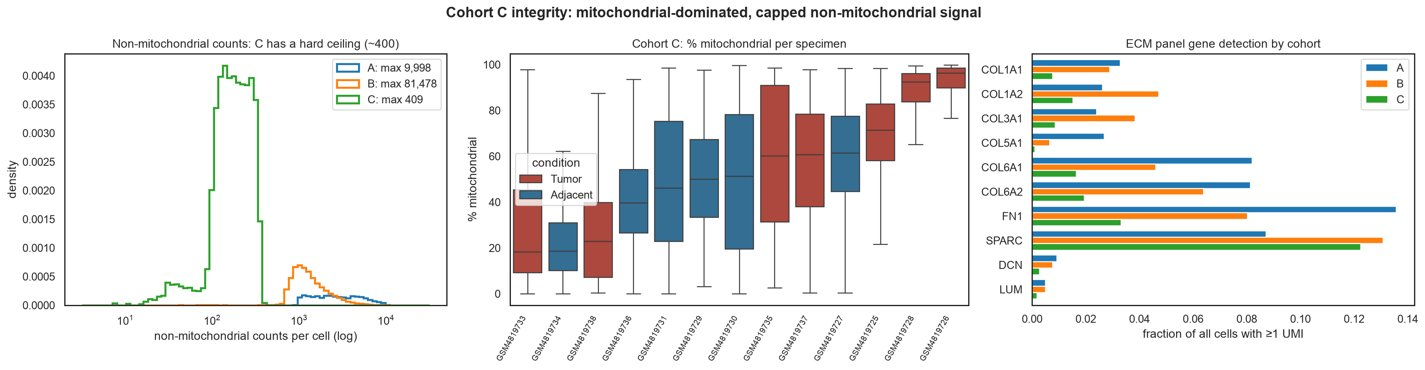

In [7]:
show(OUT / "step_2_output" / "08_cohortC_integrity.png")

In whole-specimen pseudobulk, the first principal component is almost entirely cohort
(single-nucleus vs single-cell). Tumor-vs-adjacent effects are therefore always estimated
**within** a cohort, never by pooling raw expression across cohorts.

In [8]:
r2 = table("stage2_pseudobulk_pca_r2_ALL")
r2.pivot_table(index="PC", columns="term", values="R2").join(
    r2.drop_duplicates("PC").set_index("PC")["var_explained"]
).loc[["PC1", "PC2", "PC3", "PC4"]].round(2)

,cohort,condition,donor_key,var_explained
PC,,,,
PC1,0.99,0.10,0.99,0.83
PC2,0.75,0.00,0.89,0.05
PC3,0.02,0.31,0.45,0.02
PC4,0.04,0.10,0.57,0.02


## 3 · Combining cohorts: unintegrated baseline vs Harmony

Four embeddings were compared on a stratified subsample: A alone, A + B unintegrated, and A + B
with Harmony using cohort or specimen as the batch.

**Harmony with batch = cohort was chosen.**
- It improves cohort mixing within each cell type, cell-type separation, and cross-cohort label
  transfer.
- It keeps the tumor/adjacent structure in stroma.

**Batch = specimen was rejected.** Specimen is confounded with condition, so it erases that
structure.

The embedding is used only for pictures and label transfer, never for testing.

In [9]:
m = table("stage3_integration_metrics").set_index("embedding")
tr = table("stage3_label_transfer").groupby("embedding")["balanced_accuracy"].mean()
cs = table("stage3_condition_structure")
cs = cs[cs["population"] == "Stromal (fibro+mural)"].groupby("embedding")["condition_ASW"].mean()
pd.DataFrame(
    {
        "cohort mixing (batch ASW)": m["batch_ASW"],
        "cell-type separation (ASW)": m["celltype_ASW"],
        "label transfer A↔B": tr,
        "tumor/adjacent in stroma": cs,
    }
).round(2)

,cohort mixing (batch ASW),cell-type separation (ASW),label transfer A↔B,tumor/adjacent in stroma
embedding,,,,
AB_baseline,0.49,0.62,0.72,0.24
AB_harmony,0.81,0.65,0.88,0.20
AB_harmony_spec,0.43,0.63,0.68,0.02
A_baseline,NaN,0.63,NaN,0.26


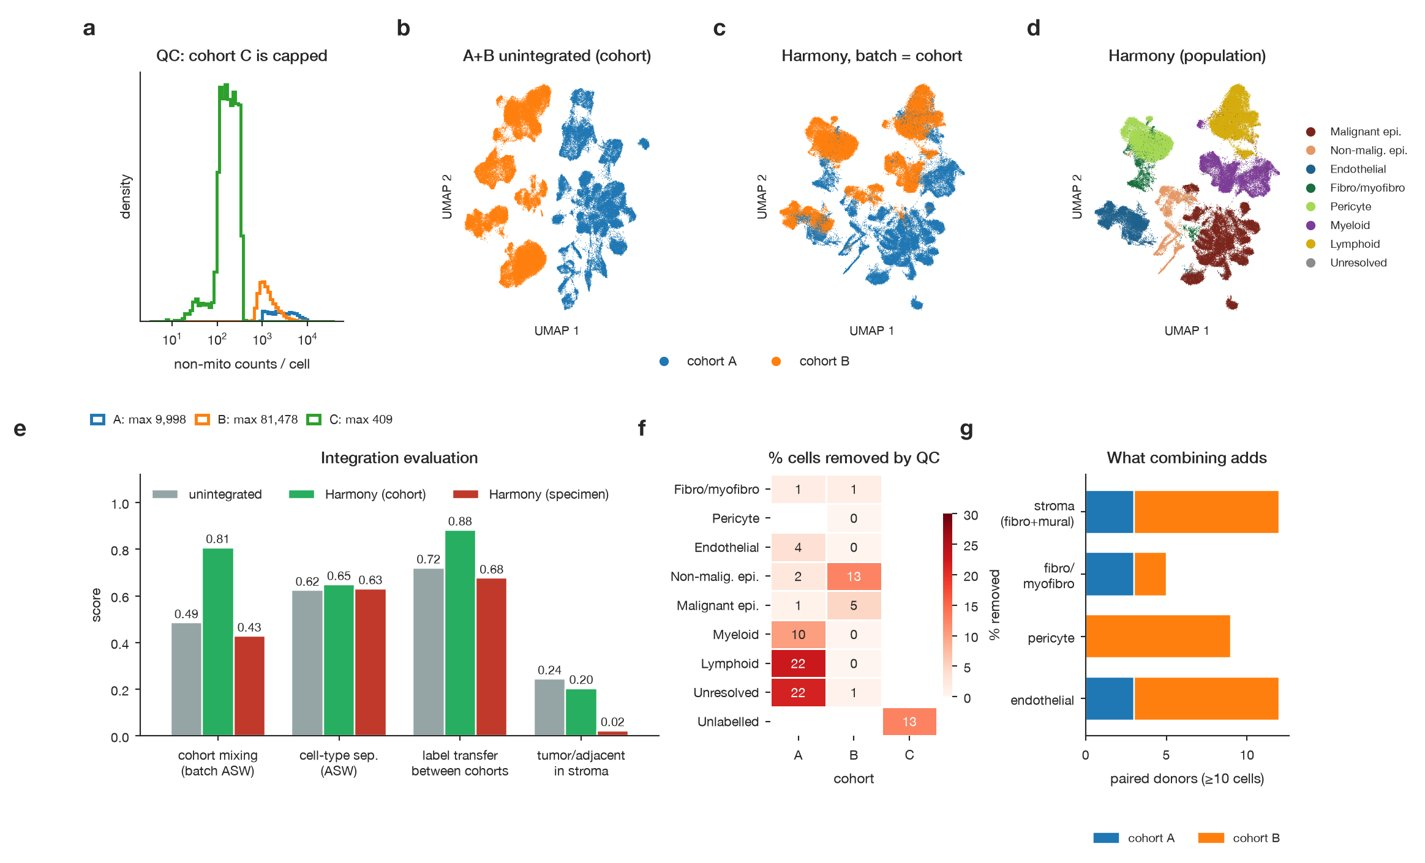

In [10]:
show(config.REPORT_DIR / "figures" / "figure1_qc_integration.png")

## 4 · Where the ECM panel is expressed; summary score; focus population

**Where it's expressed.** The stromal compartment has the highest expression of every panel gene
in both cohorts. Endothelial cells express mainly SPARC and FN1.

**Summary score.** The panel is summarised as the mean of per-gene z-scored log2-CPM. It agrees
almost perfectly with the alternatives (first principal component; log summed CPM). DCN and LUM
are fibroblast-specific and are always reported separately.

**Focus population.** The **combined fibroblast + mural compartment** was chosen. It expresses the
panel most strongly and has the best paired-donor coverage.

In [11]:
med = table("stage4_ecm_median_logcpm").set_index(["cohort", "population"])
med = med.drop(index=["ALL", "Unresolved", "Stromal_fibro_myo", "Pericyte"], level="population")
med.round(1).rename_axis(columns="median log2-CPM")

median log2-CPM                 COL1A1  COL1A2  COL3A1  COL5A1  COL6A1  COL6A2  FN1  SPARC  DCN  LUM
cohort population                                                                                   
A      Endothelial                 2.2     1.8     3.6     2.5     3.7     4.8  7.3    7.8  0.0  0.0
       Lymphoid                    1.9     1.4     0.4     2.6     2.4     3.5  3.9    3.0  0.0  0.0
       Malignant_epithelial        2.3     1.6     1.3     1.6     4.1     4.6  4.0    4.1  0.4  0.1
       Myeloid                     1.5     1.4     1.5     1.3     2.7     3.1  6.1    3.4  0.0  0.0
       Nonmalignant_epithelial     3.1     1.3     1.6     2.5     5.8     4.4  3.7    3.8  0.2  0.0
       Stromal (fibro+mural)       6.6     7.6     6.8     6.7     6.3     7.5  9.1    7.2  3.1  0.7
B      Endothelial                 1.6     2.6     5.6     1.6     4.5     5.0  8.6   10.4  0.0  0.0
       Lymphoid                    1.6     0.9     0.4     0.5     1.2     3.0  2.0    2.9  0.2  0.0
       Malignant_epithelial        3.3     3.7     1.9     0.6     4.1     4.1  4.7    5.3  0.0  0.0
       Myeloid                     0.9     0.7     0.7     0.0     1.2     0.6  4.2    2.6  0.6  0.3
       Nonmalignant_epithelial     2.3     2.3     2.0     1.0     6.4     3.8  1.9    5.3  4.2  0.0
       Stromal (fibro+mural)       6.6     8.2     7.6     4.3     7.4     8.6  8.1    9.8  6.1  4.9

In [12]:
cov = table("stage4_focus_coverage")
cov[
    cov["population"].isin(
        ["Stromal (fibro+mural)", "Stromal_fibro_myo", "Pericyte", "Endothelial"]
    )
].pivot_table(
    index="population", columns="cohort", values="paired_donors_ge10", fill_value=0
).astype(int).rename_axis(columns="paired donors (≥10 cells)")

paired donors (≥10 cells),A,B
population,,
Endothelial,3,9
Pericyte,0,9
Stromal (fibro+mural),3,9
Stromal_fibro_myo,3,2


## 5 · Tumor vs adjacent in the fibroblast + mural compartment

**What is tested.** Pseudobulk raw counts per specimen, converted to log2-CPM.

**Design.**
- Donors are the replicates; repeated tumor regions are averaged per donor.
- Each donor's tumor is compared with its own adjacent sample.
- Each cohort gets an exact sign-flip p-value. With 3 pairs the smallest possible p is 0.25.
- Cohorts are combined by fixed- and random-effects meta-analysis.

**Result.**
- **Cohort B:** the panel is higher in tumor in all 9 donors.
- **Cohort A:** with 3 pairs it is too imprecise to confirm or refute B; its interval contains B's
  estimate.

In [13]:
e = table("stage5_effects")
prim = e[e["analysis"].str.startswith("primary") & (e["feature"] == "panel_z")].set_index("cohort")
rows = [
    (
        "Cohort B (single-cell)",
        prim.loc["B", "n_donors"],
        prim.loc["B", "mean"],
        prim.loc["B", "ci_low"],
        prim.loc["B", "ci_high"],
        prim.loc["B", "n_up"],
        prim.loc["B", "p_signflip"],
    ),
    (
        "Cohort A (single-nucleus)",
        prim.loc["A", "n_donors"],
        prim.loc["A", "mean"],
        prim.loc["A", "ci_low"],
        prim.loc["A", "ci_high"],
        prim.loc["A", "n_up"],
        prim.loc["A", "p_signflip"],
    ),
    (
        "A + B, fixed effect",
        prim.loc["A+B", "n_donors"],
        prim.loc["A+B", "fixed"],
        prim.loc["A+B", "fixed_low"],
        prim.loc["A+B", "fixed_high"],
        prim.loc["A+B", "n_up"],
        prim.loc["A+B", "p_signflip"],
    ),
    (
        "A + B, random effects",
        prim.loc["A+B", "n_donors"],
        prim.loc["A+B", "random"],
        prim.loc["A+B", "random_low"],
        prim.loc["A+B", "random_high"],
        None,
        None,
    ),
]
pd.DataFrame(
    rows,
    columns=[
        "",
        "paired donors",
        "difference (SD)",
        "95% CI low",
        "95% CI high",
        "donors up",
        "sign-flip p",
    ],
).set_index("").round(3).astype({"paired donors": "Int64", "donors up": "Int64"})

,paired donors,difference (SD),95% CI low,95% CI high,donors up,sign-flip p
,,,,,,
Cohort B (single-cell),9,1.042,0.627,1.457,9,0.004
Cohort A (single-nucleus),3,0.021,-1.771,1.813,1,1.000
"A + B, fixed effect",12,0.882,0.558,1.205,10,0.003
"A + B, random effects",12,0.601,-0.391,1.592,<NA>,NaN


**Per gene, cohort B.** Fibrillar collagens, FN1 and SPARC drive the increase. DCN and LUM do not
follow; they are fibroblast-specific in a compartment that is mostly pericytes.

In [14]:
e[
    e["analysis"].str.startswith("primary")
    & (e["cohort"] == "B")
    & e["feature"].isin(config.ECM_GENES)
][["feature", "n_donors", "mean", "ci_low", "ci_high", "n_up", "q_BH"]].rename(
    columns={"mean": "log2FC"}
).astype({"n_donors": int, "n_up": int}).round(3).set_index("feature")

,n_donors,log2FC,ci_low,ci_high,n_up,q_BH
feature,,,,,,
COL1A1,9,1.309,0.177,2.442,7,0.028
COL1A2,9,2.647,1.782,3.512,9,0.010
COL3A1,9,2.573,1.508,3.639,9,0.010
COL5A1,9,0.933,-0.111,1.977,8,0.088
COL6A1,9,1.037,0.392,1.682,8,0.026
COL6A2,9,1.662,0.956,2.369,8,0.016
FN1,9,2.065,1.374,2.756,9,0.010
SPARC,9,1.743,1.174,2.313,9,0.010
DCN,9,-1.673,-4.136,0.789,3,0.169


**Robustness check (main uncertainty: compartment composition).** Could the effect come from more
fibroblasts in tumor stroma? Three checks say no:
- The effect holds in pericytes alone.
- It holds without the fibroblast genes (DCN, LUM).
- The fibroblast share does not rise.

It is also stable to every analysis choice tried, and endothelial cells show no change.

In [15]:
checks = [
    ("primary (fibroblast + mural)", "primary", "panel_z"),
    ("without DCN/LUM", "primary", "panel_z_noDCN_LUM"),
    ("pericytes only", "robustness: pericytes only", "panel_z"),
    ("≥ 20 cells per specimen", "sensitivity: >=20 cells", "panel_z"),
    ("≥ 50 cells per specimen", "sensitivity: >=50 cells", "panel_z"),
    ("one tumor region per donor", "sensitivity: one tumor region", "panel_z"),
    ("contrast: endothelial cells", "contrast: endothelial", "panel_z"),
]
b = e[e["cohort"] == "B"]
rob = pd.DataFrame(
    [
        b[b["analysis"].str.startswith(a) & (b["feature"] == f)]
        .iloc[0][["n_donors", "mean", "ci_low", "ci_high", "n_up"]]
        .rename(label)
        for label, a, f in checks
    ]
)
mm = table("stage5_mixed_model").set_index("cohort").loc["B"]
rob.loc["mixed model, all specimens"] = [
    mm["donors"],
    mm["estimate_z"],
    mm["ci_low"],
    mm["ci_high"],
    None,
]
fs = table("stage5_B_fibroblast_share_test").iloc[0]
rob.loc["fibroblast share (tumor − adjacent)"] = [
    fs["n_donors"],
    fs["mean"],
    fs["ci_low"],
    fs["ci_high"],
    fs["n_up"],
]
rob.rename(columns={"mean": "difference"}).round(3).astype(
    {"n_donors": "Int64", "n_up": "Int64"}
).rename_axis("cohort B check")

,n_donors,difference,ci_low,ci_high,n_up
cohort B check,,,,,
primary (fibroblast + mural),9,1.042,0.627,1.457,9
without DCN/LUM,9,1.411,0.962,1.861,9
pericytes only,9,1.273,0.848,1.698,9
≥ 20 cells per specimen,9,1.042,0.627,1.457,9
≥ 50 cells per specimen,8,1.068,0.593,1.544,8
one tumor region per donor,9,1.044,0.632,1.455,9
contrast: endothelial cells,9,0.129,-0.257,0.516,7
"mixed model, all specimens",11,1.106,0.851,1.361,<NA>
fibroblast share (tumor − adjacent),9,0.044,-0.055,0.144,2


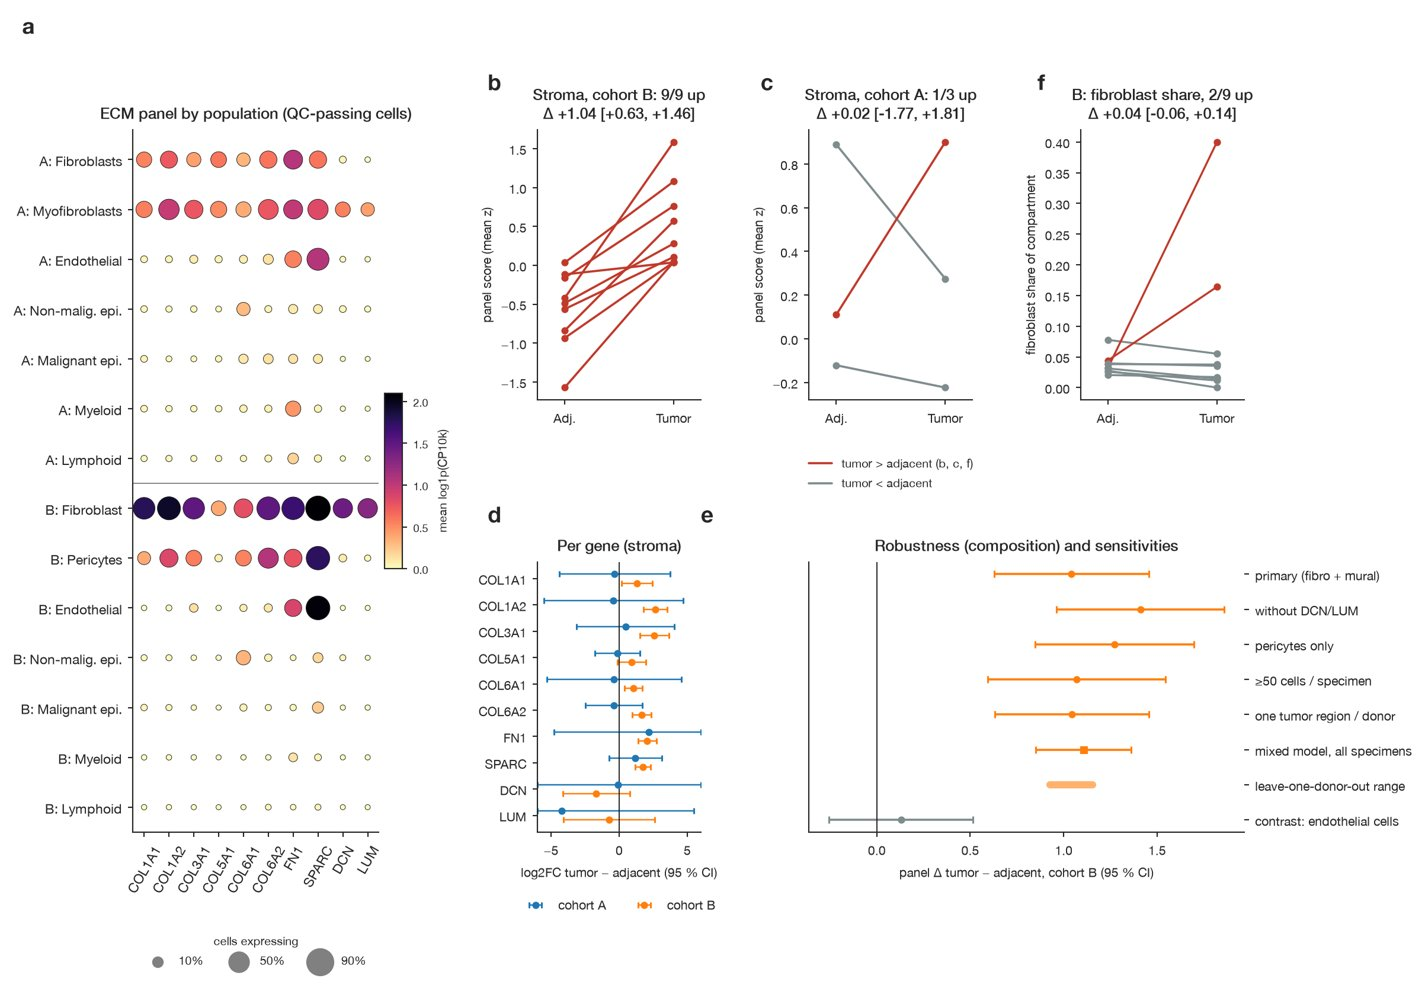

In [16]:
show(config.REPORT_DIR / "figures" / "figure2_ecm_program.png")

## 6 · Linked bulk RNA and protein

**Crosswalk.** Every cohort A specimen was traced through the crosswalk to real bulk columns. No
pair was invented from donor identity.
- Only **3 donors** have clean tumor and adjacent links. C3N-00242 is a sensitivity case.
- The matched subset is therefore too small to decide.

**Context from the whole CPTAC cohort.** It comes from the same study as cohort A (72 RNA and
80 protein pairs) and shows the same gene pattern as cohort B.

**Composition.** Bulk differences depend strongly on composition. Tumors lose fibroblast markers
but gain mural and endothelial markers, so the bulk rise may partly reflect expansion of those
tissues.

In [17]:
table("stage6_specimen_inclusion")["reason"].value_counts().rename("specimens").to_frame()

,specimens
reason,
"linked, but donor has no linked adjacent specimen",20
matched pair (primary link),6
no author bulk link (no pair invented),5
protein from a different parent specimen: excluded,1
sensitivity only (this donor's tumor link is flagged),1
protein from two parent specimens: sensitivity only,1


In [18]:
e6 = table("stage6_effects")
e6 = e6[(e6["feature"] == "panel_z") & ~e6["scope"].str.contains("C3N-00242")]
e6.assign(scope=e6["scope"].str.split(" \\(").str[0]).set_index(["scope", "assay"])[
    ["n_donors", "mean", "ci_low", "ci_high", "n_up", "p_signflip"]
].rename(columns={"mean": "difference (SD)"}).round(3).assign(
    # n >= 72 uses 100,000 random sign patterns, so 0 means p < 1e-5
    p_signflip=lambda d: d["p_signflip"].map(lambda p: "< 1e-5" if p == 0 else f"{p:.3f}")
)

n_donors  difference (SD)  ci_low  ci_high  n_up p_signflip
scope            assay                                                                                        
matched subset   snRNA stroma                             3           -0.219  -1.523    1.086     1      0.500
                 snRNA whole specimen                     3           -0.139  -2.634    2.357     1      1.000
                 bulk RNA                                 3            0.481  -1.841    2.803     2      0.500
                 bulk protein                             3            0.259  -0.728    1.245     2      0.500
full bulk cohort bulk RNA (all paired donors)            72            0.519   0.309    0.729    54     < 1e-5
                 bulk protein (all paired donors)        80            0.680   0.493    0.867    67     < 1e-5

In [19]:
table("stage6_composition_corr")[
    [
        "marker_set",
        "mean_marker_change_z",
        "frac_donors_marker_down",
        "spearman_rho",
        "spearman_rho_noDCN_LUM",
    ]
].round(2).set_index("marker_set")

,mean_marker_change_z,frac_donors_marker_down,spearman_rho,spearman_rho_noDCN_LUM
marker_set,,,,
mural,0.56,0.29,0.62,0.62
fibroblast,-1.54,0.97,0.77,0.68
endothelial,1.63,0.03,0.26,0.29


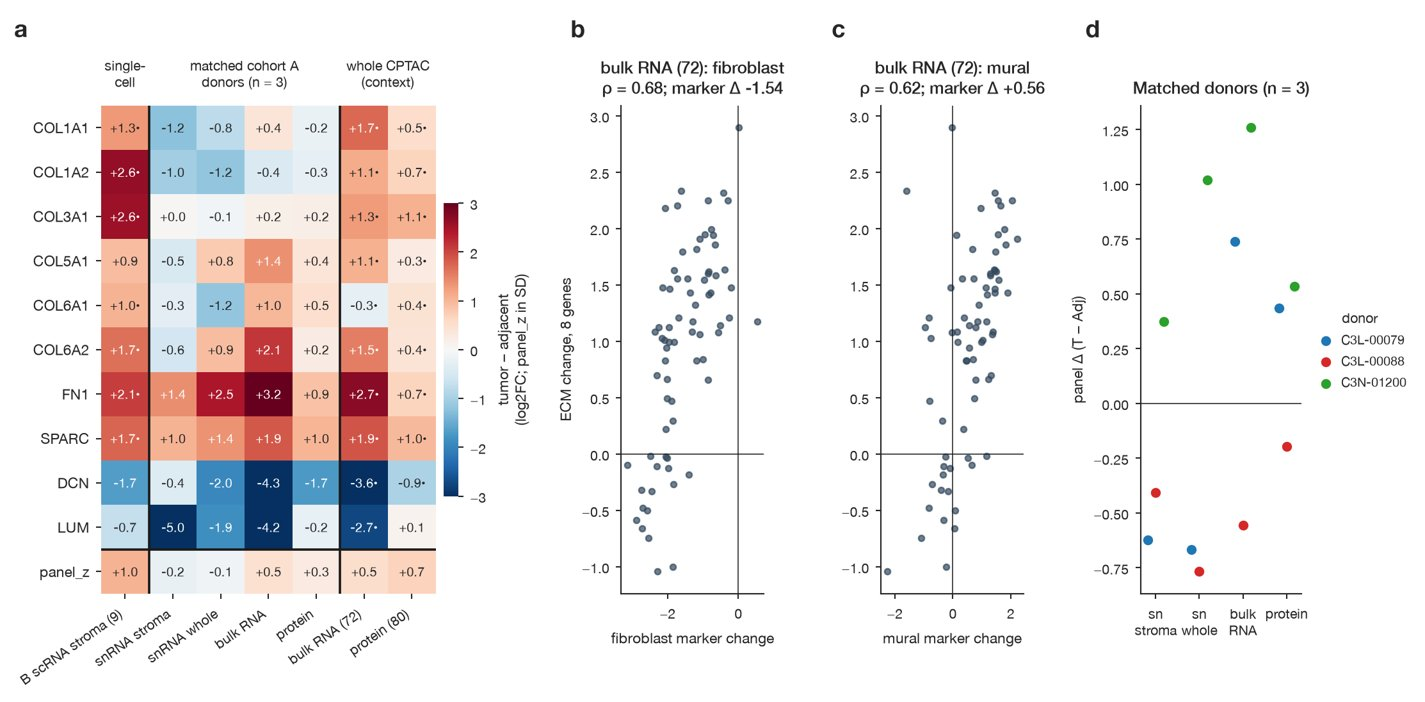

In [20]:
show(config.REPORT_DIR / "figures" / "figure3_multimodal.png")

## 7 · Reproducibility check

`opengo all` was re-run from the raw inputs into a separate folder and every table was compared
with the committed results:
- 63 of 65 tables are identical;
- one differs at the 1e-9 level (floating point);
- in one, only the Leiden-based ARI/NMI on the Harmony embeddings varies.

No number quoted in the report changed.

In [21]:
table("rebuild_comparison")["status"].str.split(" ").str[0].value_counts().rename(
    "tables"
).to_frame()

,tables
status,
identical,63
≈,2
